In [1]:
!pip install ucimlrepo -q

In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

dataset = fetch_ucirepo(id=697)
df = dataset.data.features.copy()
df["Target"] = dataset.data.targets["Target"]

print(df.shape)
df.head()

(4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [3]:
df["Dropout"] = (df["Target"] == "Dropout").astype(int)
print(df["Dropout"].value_counts())
print(df["Dropout"].value_counts(normalize=True).round(3))

Dropout
0    3003
1    1421
Name: count, dtype: int64
Dropout
0    0.679
1    0.321
Name: proportion, dtype: float64


In [4]:
print("Valeurs manquantes :", df.isna().sum().sum())
df.info()

Valeurs manquantes : 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 38 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualifica

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital Status,4424.0,1.178571,0.605747,1.00,1.00,1.000000,1.000000,6.000000
Application mode,4424.0,18.669078,17.484682,1.00,1.00,17.000000,39.000000,57.000000
Application order,4424.0,1.727848,1.313793,0.00,1.00,1.000000,2.000000,9.000000
Course,4424.0,8856.642631,2063.566416,33.00,9085.00,9238.000000,9556.000000,9991.000000
Daytime/evening attendance,4424.0,0.890823,0.311897,0.00,1.00,1.000000,1.000000,1.000000
Previous qualification,4424.0,4.577758,10.216592,1.00,1.00,1.000000,1.000000,43.000000
Previous qualification (grade),4424.0,132.613314,13.188332,95.00,125.00,133.100000,140.000000,190.000000
Nacionality,4424.0,1.873192,6.914514,1.00,1.00,1.000000,1.000000,109.000000
Mother's qualification,4424.0,19.561935,15.603186,1.00,2.00,19.000000,37.000000,44.000000
Father's qualification,4424.0,22.275316,15.343108,1.00,3.00,19.000000,37.000000,44.000000


In [6]:
df.drop(columns=["Target", "Dropout"]).nunique().sort_values().head(25)

Daytime/evening attendance                         2
Displaced                                          2
Debtor                                             2
Educational special needs                          2
International                                      2
Scholarship holder                                 2
Gender                                             2
Tuition fees up to date                            2
Marital Status                                     6
Application order                                  8
Inflation rate                                     9
Curricular units 2nd sem (without evaluations)    10
GDP                                               10
Unemployment rate                                 10
Curricular units 1st sem (without evaluations)    11
Previous qualification                            17
Course                                            17
Application mode                                  18
Curricular units 2nd sem (credited)           

In [7]:
import plotly.express as px

col = "Tuition fees up to date"
taux = df.groupby(col)["Dropout"].mean().reset_index()
px.bar(taux, x=col, y="Dropout", title=f"Taux de décrochage selon : {col}").show()

In [8]:
corr = df.drop(columns="Target").corr()["Dropout"].drop("Dropout").sort_values()
print("Les plus négatives (protègent du décrochage) :")
print(corr.head(5))
print("\nLes plus positives (augmentent le décrochage) :")
print(corr.tail(5))

Les plus négatives (protègent du décrochage) :
Curricular units 2nd sem (grade)      -0.571792
Curricular units 2nd sem (approved)   -0.569500
Curricular units 1st sem (grade)      -0.480669
Curricular units 1st sem (approved)   -0.479112
Tuition fees up to date               -0.429149
Name: Dropout, dtype: float64

Les plus positives (augmentent le décrochage) :
Marital Status       0.093712
Application mode     0.198458
Gender               0.203983
Debtor               0.229407
Age at enrollment    0.254215
Name: Dropout, dtype: float64


In [9]:
# X = variables explicatives, y = cible binaire
X = df.drop(columns=["Target", "Dropout"])
y = df["Dropout"]

# Catégories codées par des entiers (le code n'a aucun ordre réel)
categorical_cols = [
    "Marital Status", "Application mode", "Course", "Previous qualification",
    "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation",
]

# Variables binaires (0/1) : on les laisse telles quelles
binary_cols = [c for c in X.columns if X[c].nunique() == 2]

# Le reste est numérique : on le normalisera
numeric_cols = [c for c in X.columns if c not in categorical_cols + binary_cols]

print("Catégorielles :", len(categorical_cols))
print("Binaires      :", len(binary_cols))
print("Numériques    :", len(numeric_cols))

Catégorielles : 9
Binaires      : 8
Numériques    : 19


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)
print("Décrochage train :", y_train.mean().round(3))
print("Décrochage test  :", y_test.mean().round(3))

(3539, 36) (885, 36)
Décrochage train : 0.321
Décrochage test  : 0.321


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ("bin", "passthrough", binary_cols),
])

preprocessor.fit(X_train)                    # apprend sur le TRAIN uniquement
X_train_t = preprocessor.transform(X_train)
X_test_t = preprocessor.transform(X_test)

print("Avant :", X_train.shape[1], "colonnes")
print("Après :", X_train_t.shape[1], "colonnes")

Avant : 36 colonnes
Après : 235 colonnes


In [12]:
import numpy as np
print("Valeurs manquantes après transformation :", np.isnan(X_train_t).sum())
print("Moyenne des variables numériques (train) ~ 0 :",
      X_train_t[:, :len(numeric_cols)].mean().round(3))

Valeurs manquantes après transformation : 0
Moyenne des variables numériques (train) ~ 0 : -0.0


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

SEED = 42

# modèle de base + petite grille d'hyperparamètres (préfixe "clf__" = étape du pipeline)
configs = {
    "Régression logistique": (
        LogisticRegression(max_iter=2000),
        {"clf__C": [0.01, 0.1, 1, 10]},
    ),
    "Arbre de décision": (
        DecisionTreeClassifier(random_state=SEED),
        {"clf__max_depth": [3, 5, 8], "clf__min_samples_leaf": [5, 20]},
    ),
    "k-NN": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [5, 11, 21]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
        {"clf__max_depth": [8, 16], "clf__min_samples_leaf": [1, 5]},
    ),
    "XGBoost": (
        XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1),
        {"clf__n_estimators": [200, 400],
         "clf__max_depth": [3, 5],
         "clf__learning_rate": [0.05, 0.1]},
    ),
}

In [14]:
import time

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
best_models, cv_results = {}, {}

for name, (estimator, grid) in configs.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("clf", estimator)])
    search = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=-1)
    t0 = time.time()
    search.fit(X_train, y_train)            # X_train brut : le pipeline s'occupe de tout
    best_models[name] = search.best_estimator_
    cv_results[name] = (search.best_score_, search.best_params_, time.time() - t0)
    print(f"{name:22s} AUC CV = {search.best_score_:.3f} | {search.best_params_} | {time.time()-t0:.0f}s")

Régression logistique  AUC CV = 0.921 | {'clf__C': 1} | 3s
Arbre de décision      AUC CV = 0.881 | {'clf__max_depth': 5, 'clf__min_samples_leaf': 20} | 1s
k-NN                   AUC CV = 0.876 | {'clf__n_neighbors': 21} | 0s
Random Forest          AUC CV = 0.915 | {'clf__max_depth': 16, 'clf__min_samples_leaf': 1} | 8s
XGBoost                AUC CV = 0.918 | {'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__n_estimators': 400} | 7s


In [15]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

best_models_v1 = dict(best_models)          # copie de secours de la version actuelle

# --- XGBoost : recherche aléatoire, plages plus larges ---
pipe_xgb = Pipeline([("prep", clone(preprocessor)),
                     ("clf", XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=1))])
param_xgb = {
    "clf__n_estimators": randint(200, 700),
    "clf__max_depth": randint(2, 6),
    "clf__learning_rate": loguniform(0.01, 0.2),
    "clf__subsample": uniform(0.6, 0.4),          # entre 0,6 et 1,0
    "clf__colsample_bytree": uniform(0.5, 0.5),   # entre 0,5 et 1,0
    "clf__min_child_weight": randint(1, 10),
    "clf__reg_lambda": loguniform(0.5, 20),
}
search_xgb = RandomizedSearchCV(pipe_xgb, param_xgb, n_iter=40, scoring="roc_auc",
                                cv=cv, n_jobs=-1, random_state=SEED)
search_xgb.fit(X_train, y_train)

# --- Régression logistique : grille de C plus fine ---
pipe_lr = Pipeline([("prep", clone(preprocessor)),
                    ("clf", LogisticRegression(max_iter=3000))])
search_lr = GridSearchCV(pipe_lr, {"clf__C": [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
                         scoring="roc_auc", cv=cv, n_jobs=-1)
search_lr.fit(X_train, y_train)

# --- On garde la nouvelle version seulement si la VALIDATION CROISÉE s'améliore ---
for name, s in [("XGBoost", search_xgb), ("Régression logistique", search_lr)]:
    old, new = cv_results[name][0], s.best_score_
    print(f"{name:22s} AUC CV avant = {old:.4f} | après = {new:.4f}")
    print("   meilleurs paramètres :", s.best_params_)
    if new > old + 0.001:
        best_models[name] = s.best_estimator_
        cv_results[name] = (new, s.best_params_, 0)
        print("   -> nouvelle version retenue")
    else:
        print("   -> gain trop faible, on garde l'ancienne version")

XGBoost                AUC CV avant = 0.9176 | après = 0.9192
   meilleurs paramètres : {'clf__colsample_bytree': np.float64(0.5610439773503366), 'clf__learning_rate': np.float64(0.02907730652732417), 'clf__max_depth': 3, 'clf__min_child_weight': 1, 'clf__n_estimators': 584, 'clf__reg_lambda': np.float64(1.159139775776865), 'clf__subsample': np.float64(0.7708431154505025)}
   -> nouvelle version retenue
Régression logistique  AUC CV avant = 0.9213 | après = 0.9213
   meilleurs paramètres : {'clf__C': 1}
   -> gain trop faible, on garde l'ancienne version


In [16]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score

rows = []
for name, model in best_models.items():
    proba_test = model.predict_proba(X_test)[:, 1]
    pred = (proba_test >= 0.5).astype(int)
    rows.append({
        "Modèle": name,
        "AUC train": roc_auc_score(y_train, model.predict_proba(X_train)[:, 1]),
        "AUC CV": cv_results[name][0],
        "AUC test": roc_auc_score(y_test, proba_test),
        "Précision": precision_score(y_test, pred),
        "Rappel": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })

comparatif = pd.DataFrame(rows).set_index("Modèle").round(3).sort_values("AUC test", ascending=False)
comparatif

,AUC train,AUC CV,AUC test,Précision,Rappel,F1
Modèle,,,,,,
XGBoost,0.961,0.919,0.936,0.888,0.757,0.817
Régression logistique,0.936,0.921,0.932,0.882,0.761,0.817
Random Forest,0.998,0.915,0.926,0.889,0.708,0.788
k-NN,0.914,0.876,0.887,0.910,0.535,0.674
Arbre de décision,0.901,0.881,0.885,0.804,0.722,0.761


In [17]:
import plotly.graph_objects as go
from sklearn.metrics import roc_curve

probas = {n: m.predict_proba(X_test)[:, 1] for n, m in best_models.items()}

fig = go.Figure()
for n, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines",
                             name=f"{n} (AUC={roc_auc_score(y_test, p):.3f})"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines",
                         line=dict(dash="dash", color="gray"), name="Hasard"))
fig.update_layout(title="Courbes ROC (jeu de test)",
                  xaxis_title="Taux de faux positifs", yaxis_title="Taux de vrais positifs (rappel)")
fig.show()

In [18]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig = go.Figure()
for n, p in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, p)
    fig.add_trace(go.Scatter(x=rec, y=prec, mode="lines",
                             name=f"{n} (PR-AUC={average_precision_score(y_test, p):.3f})"))
fig.add_hline(y=y_test.mean(), line_dash="dash", line_color="gray",
              annotation_text="Hasard (taux de décrochage)")
fig.update_layout(title="Courbes précision-rappel (jeu de test)",
                  xaxis_title="Rappel", yaxis_title="Précision")
fig.show()

In [19]:
from sklearn.metrics import confusion_matrix
import plotly.express as px

model_name, seuil = "XGBoost", 0.5
pred = (probas[model_name] >= seuil).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print(f"Vrais positifs (décrocheurs détectés)   : {tp}")
print(f"Faux négatifs (décrocheurs ratés)       : {fn}")
print(f"Faux positifs (fausses alertes)         : {fp}")
print(f"Vrais négatifs (non-décrocheurs OK)     : {tn}")

px.imshow([[tn, fp], [fn, tp]], text_auto=True,
          x=["Prédit : reste", "Prédit : décroche"], y=["Réel : reste", "Réel : décroche"],
          title=f"Matrice de confusion - {model_name} (seuil {seuil})").show()

Vrais positifs (décrocheurs détectés)   : 215
Faux négatifs (décrocheurs ratés)       : 69
Faux positifs (fausses alertes)         : 27
Vrais négatifs (non-décrocheurs OK)     : 574


In [20]:
import numpy as np

p = probas["XGBoost"]
rows = []
for s in np.arange(0.1, 0.91, 0.1):
    pred = (p >= s).astype(int)
    rows.append({"Seuil": round(s, 1),
                 "Précision": precision_score(y_test, pred, zero_division=0),
                 "Rappel": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "Étudiants alertés": int(pred.sum())})
pd.DataFrame(rows).round(3)

,Seuil,Précision,Rappel,F1,Étudiants alertés
0,0.1,0.536,0.951,0.685,504
1,0.2,0.695,0.891,0.781,364
2,0.3,0.786,0.856,0.820,309
3,0.4,0.824,0.806,0.815,278
4,0.5,0.888,0.757,0.817,242
5,0.6,0.914,0.715,0.802,222
6,0.7,0.945,0.662,0.778,199
7,0.8,0.965,0.588,0.731,173
8,0.9,0.992,0.440,0.610,126


In [21]:
print("Avant la fusion :")
print(df["Target"].value_counts())
print(df["Target"].value_counts(normalize=True).round(3))

print("\nAprès la fusion :")
print(df["Dropout"].value_counts())
print("Rapport :", round((df["Dropout"] == 0).sum() / (df["Dropout"] == 1).sum(), 2), "pour 1")

print("\nTrain :", y_train.value_counts().to_dict())
print("Test  :", y_test.value_counts().to_dict())

Avant la fusion :
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

Après la fusion :
Dropout
0    3003
1    1421
Name: count, dtype: int64
Rapport : 2.11 pour 1

Train : {0: 2402, 1: 1137}
Test  : {0: 601, 1: 284}


In [22]:
from sklearn.metrics import accuracy_score, average_precision_score

rows = []
for name, model in best_models.items():
    p = model.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({"Modèle": name,
                 "AUC": roc_auc_score(y_test, p),
                 "PR-AUC": average_precision_score(y_test, p),
                 "Accuracy": accuracy_score(y_test, pred),
                 "Précision": precision_score(y_test, pred),
                 "Rappel": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})
pd.DataFrame(rows).set_index("Modèle").round(3).sort_values("AUC", ascending=False)

,AUC,PR-AUC,Accuracy,Précision,Rappel,F1
Modèle,,,,,,
XGBoost,0.936,0.909,0.892,0.888,0.757,0.817
Régression logistique,0.932,0.903,0.890,0.882,0.761,0.817
Random Forest,0.926,0.895,0.878,0.889,0.708,0.788
k-NN,0.887,0.828,0.834,0.910,0.535,0.674
Arbre de décision,0.885,0.835,0.854,0.804,0.722,0.761


In [23]:
import joblib, json, os, shutil, sklearn, xgboost, pandas

os.makedirs("artifacts", exist_ok=True)

# les 5 modèles (pipeline = préprocesseur + modèle), compressés pour limiter la taille
noms_fichiers = {
    "XGBoost": "xgboost",
    "Régression logistique": "logreg",
    "Random Forest": "random_forest",
    "k-NN": "knn",
    "Arbre de décision": "decision_tree",
}
for nom, fichier in noms_fichiers.items():
    joblib.dump(best_models[nom], f"artifacts/{fichier}_pipeline.joblib", compress=3)

# le jeu de test (pour l'API et pour choisir un étudiant plus tard)
test_df = X_test.copy()
test_df["Dropout"] = y_test
test_df.to_csv("artifacts/test_set.csv", index=False)

# informations dont l'API aura besoin
meta = {
    "target": "Dropout",
    "features": list(X.columns),
    "categorical": categorical_cols,
    "binary": binary_cols,
    "numeric": numeric_cols,
    "default_threshold": 0.3,
}
json.dump(meta, open("artifacts/meta.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

shutil.make_archive("artifacts", "zip", "artifacts")

for f in sorted(os.listdir("artifacts")):
    print(f"{f:35s} {os.path.getsize(f'artifacts/{f}') / 1e6:.1f} Mo")
print("scikit-learn :", sklearn.__version__)
print("xgboost      :", xgboost.__version__)
print("pandas       :", pandas.__version__)

decision_tree_pipeline.joblib       0.0 Mo
knn_pipeline.joblib                 0.4 Mo
logreg_pipeline.joblib              0.0 Mo
meta.json                           0.0 Mo
random_forest_pipeline.joblib       2.8 Mo
test_set.csv                        0.1 Mo
xgboost_pipeline.joblib             0.1 Mo
scikit-learn : 1.6.1
xgboost      : 3.4.1
pandas       : 2.3.3


In [25]:
!pip install shap lime -q

In [26]:
import numpy as np, pandas as pd, shap, matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

xgb_pipe = best_models["XGBoost"]
lr_pipe = best_models["Régression logistique"]
prep = xgb_pipe.named_steps["prep"]
raw_cols = list(X_train.columns)                    # les 36 variables d'origine

# Après l'encodage, une variable catégorielle devient plusieurs colonnes 0/1.
# On repère de quelle variable d'origine vient chaque colonne encodée.
out_names = list(prep.get_feature_names_out())      # ex. 'cat__Course_9500', 'num__Admission grade'
cats_longest_first = sorted(categorical_cols, key=len, reverse=True)

def origin(name):
    kind, rest = name.split("__", 1)
    if kind == "cat":
        for c in cats_longest_first:
            if rest.startswith(c + "_"):
                return c
    return rest

M = np.zeros((len(out_names), len(raw_cols)))        # matrice de regroupement : 235 x 36
for j, n in enumerate(out_names):
    M[j, raw_cols.index(origin(n))] = 1
print(len(out_names), "colonnes encodées ->", len(raw_cols), "variables d'origine")

235 colonnes encodées -> 36 variables d'origine


In [27]:
Xt_test = prep.transform(X_test)
explainer = shap.TreeExplainer(xgb_pipe.named_steps["clf"])
sv = explainer.shap_values(Xt_test)             # contributions en log-odds : (885, 235)
sv_raw = sv @ M                                 # regroupées par variable d'origine : (885, 36)
base = float(np.ravel(explainer.expected_value)[0])

# Vérification : valeur de base + somme des contributions = prédiction (en log-odds)
p = xgb_pipe.predict_proba(X_test)[:, 1]
logit = np.log(p / (1 - p))
print("Écart maximal entre la décomposition SHAP et la prédiction :",
      float(np.abs(base + sv_raw.sum(axis=1) - logit).max()))

imp = pd.Series(np.abs(sv_raw).mean(axis=0), index=raw_cols).sort_values(ascending=False)
print("\nImportance SHAP (moyenne des |contributions|, en log-odds) :")
print(imp.head(10).round(3))

Écart maximal entre la décomposition SHAP et la prédiction : 1.614418943063356e-05

Importance SHAP (moyenne des |contributions|, en log-odds) :
Curricular units 2nd sem (approved)    0.992
Tuition fees up to date                0.431
Curricular units 1st sem (approved)    0.339
Curricular units 2nd sem (grade)       0.303
Age at enrollment                      0.275
Course                                 0.190
Curricular units 2nd sem (enrolled)    0.183
Unemployment rate                      0.153
Scholarship holder                     0.152
Gender                                 0.124
dtype: float64


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1437: RuntimeWarning:

All-NaN slice encountered



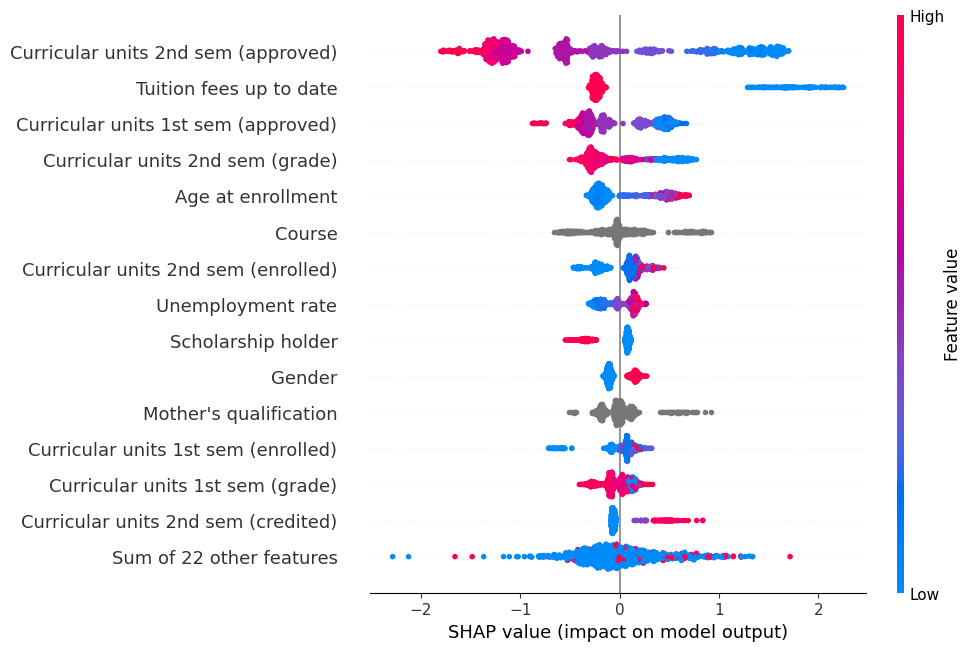

In [28]:
data_color = X_test.astype(float).copy()
data_color[categorical_cols] = np.nan            # un code de catégorie n'a pas d'ordre : points gris
expl = shap.Explanation(values=sv_raw, base_values=np.full(len(sv_raw), base),
                        data=data_color.values, feature_names=raw_cols)
shap.plots.beeswarm(expl, max_display=15)

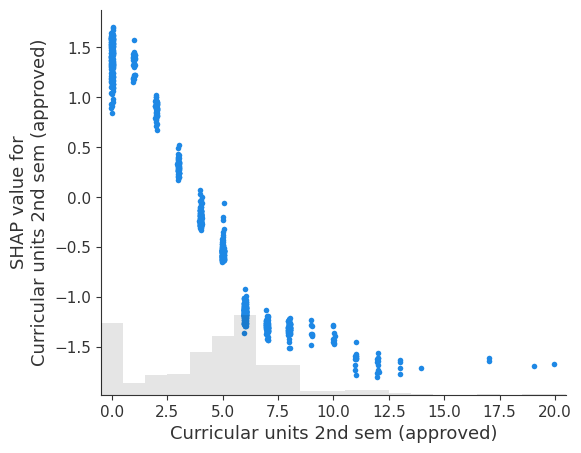

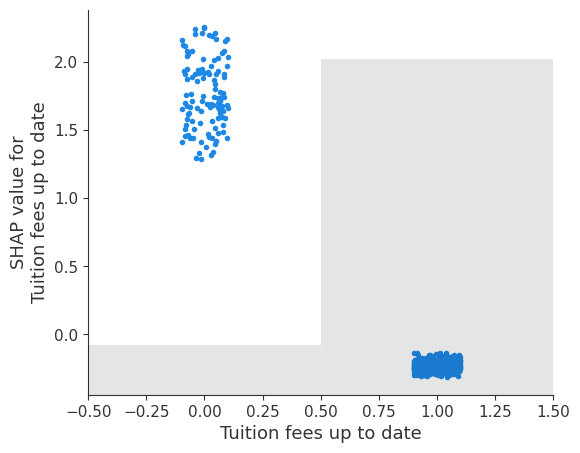

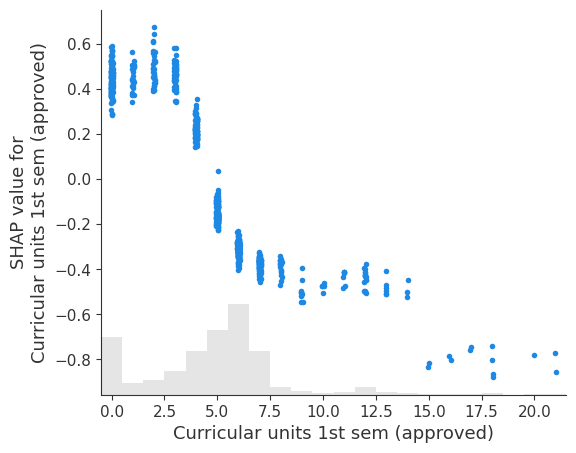

In [29]:
top_num = [c for c in imp.index if c not in categorical_cols][:3]
for c in top_num:
    shap.plots.scatter(expl[:, c])

                                        XGBoost  Régression logistique
Curricular units 2nd sem (approved)      0.0969                 0.1961
Tuition fees up to date                  0.0329                 0.0286
Curricular units 1st sem (approved)      0.0096                 0.0600
Curricular units 2nd sem (grade)         0.0077                 0.0044
Course                                   0.0057                 0.0073
Curricular units 2nd sem (credited)      0.0052                 0.0126
Curricular units 2nd sem (enrolled)      0.0048                 0.0291
Unemployment rate                        0.0042                 0.0103
Age at enrollment                        0.0038                 0.0030
Curricular units 2nd sem (evaluations)   0.0026                 0.0009


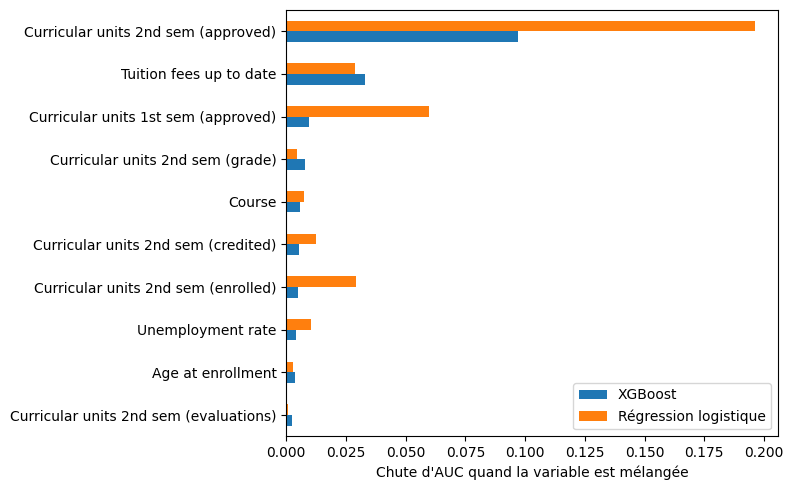

In [30]:
def perm(model, name):
    r = permutation_importance(model, X_test, y_test, scoring="roc_auc",
                               n_repeats=5, random_state=42, n_jobs=-1)
    return pd.Series(r.importances_mean, index=raw_cols, name=name)

perm_df = pd.concat([perm(xgb_pipe, "XGBoost"), perm(lr_pipe, "Régression logistique")], axis=1)
perm_df = perm_df.sort_values("XGBoost", ascending=False)
print(perm_df.head(10).round(4))

ax = perm_df.head(10)[::-1].plot.barh(figsize=(8, 5))
ax.set_xlabel("Chute d'AUC quand la variable est mélangée")
plt.tight_layout(); plt.show()

In [31]:
imp_xgb = pd.Series(xgb_pipe.named_steps["clf"].feature_importances_ @ M,
                    index=raw_cols).sort_values(ascending=False)
coef_lr = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=out_names)
coef_top = coef_lr.reindex(coef_lr.abs().sort_values(ascending=False).index).head(10)

print("XGBoost : importance propre (regroupée par variable)")
print(imp_xgb.head(10).round(3))
print("\nRégression logistique : 10 plus gros coefficients (colonnes encodées)")
print(coef_top.round(2))

ranks = pd.DataFrame({
    "SHAP (XGBoost)": imp.rank(ascending=False),
    "Permutation (XGBoost)": perm_df["XGBoost"].rank(ascending=False),
    "Permutation (Rég. log.)": perm_df["Régression logistique"].rank(ascending=False),
    "Importance propre (XGBoost)": imp_xgb.rank(ascending=False),
}).sort_values("SHAP (XGBoost)").head(10).astype(int)
print("\nRang de chaque variable selon les 4 méthodes (1 = la plus importante) :")
print(ranks.to_string())

XGBoost : importance propre (regroupée par variable)
Course                                 0.138
Curricular units 2nd sem (approved)    0.089
Mother's occupation                    0.073
Application mode                       0.072
Father's occupation                    0.066
Father's qualification                 0.061
Mother's qualification                 0.060
Curricular units 1st sem (approved)    0.054
Tuition fees up to date                0.053
Curricular units 2nd sem (grade)       0.045
dtype: float64

Régression logistique : 10 plus gros coefficients (colonnes encodées)
bin__Tuition fees up to date               -2.29
num__Curricular units 2nd sem (approved)   -1.82
cat__Mother's occupation_191               -1.71
cat__Mother's qualification_4              -1.33
cat__Mother's occupation_0                  1.21
cat__Father's occupation_90                 1.13
cat__Mother's occupation_8                  1.08
cat__Course_9853                            1.02
num__Curricular uni

In [32]:
sensibles = ["Gender", "Age at enrollment", "Marital Status", "Nacionality", "International"]
print("Part de l'importance SHAP portée par chaque variable sensible :")
print((imp[sensibles] / imp.sum()).round(3).to_string())
print("Total :", round(imp[sensibles].sum() / imp.sum(), 3))

# 1) Test contrefactuel : on inverse le genre de tous les étudiants du test
thr = 0.3
p0 = xgb_pipe.predict_proba(X_test)[:, 1]
X_flip = X_test.copy()
X_flip["Gender"] = 1 - X_flip["Gender"]
p1 = xgb_pipe.predict_proba(X_flip)[:, 1]
print(f"\nDécisions qui changent si on inverse le genre (seuil {thr}) :",
      int(((p0 >= thr) != (p1 >= thr)).sum()), "sur", len(X_test))
print("Variation moyenne de la probabilité :", round(float(np.abs(p1 - p0).mean()), 3))

# 2) Les erreurs du modèle sont-elles réparties de la même façon selon les groupes ?
def par_groupe(groupes, nom):
    rows = []
    for val in pd.Series(groupes).dropna().unique():
        m = (groupes == val).values
        pred, yy = p0[m] >= thr, y_test.values[m]
        rows.append({nom: str(val), "Effectif": int(m.sum()),
                     "Abandon réel": yy.mean(), "Part signalée": pred.mean(),
                     "Rappel": (pred & (yy == 1)).sum() / max((yy == 1).sum(), 1),
                     "Fausses alertes": (pred & (yy == 0)).sum() / max((yy == 0).sum(), 1)})
    return pd.DataFrame(rows).sort_values(nom).round(3).to_string(index=False)

age = pd.cut(X_test["Age at enrollment"], bins=[0, 19, 22, 25, 100],
             labels=["19 ans ou moins", "20-22 ans", "23-25 ans", "plus de 25 ans"])
print("\nPar genre :");           print(par_groupe(X_test["Gender"], "Genre"))
print("\nPar âge à l'inscription :"); print(par_groupe(age, "Âge"))
print("\nPar statut international :"); print(par_groupe(X_test["International"], "International"))

Part de l'importance SHAP portée par chaque variable sensible :
Gender               0.028
Age at enrollment    0.061
Marital Status       0.003
Nacionality          0.002
International        0.000
Total : 0.094

Décisions qui changent si on inverse le genre (seuil 0.3) : 25 sur 885
Variation moyenne de la probabilité : 0.027

Par genre :
Genre  Effectif  Abandon réel  Part signalée  Rappel  Fausses alertes
    0       564         0.245          0.262   0.833            0.077
    1       321         0.455          0.502   0.877            0.189

Par âge à l'inscription :
            Âge  Effectif  Abandon réel  Part signalée  Rappel  Fausses alertes
19 ans ou moins       412         0.204          0.223   0.774            0.082
      20-22 ans       184         0.261          0.261   0.729            0.096
      23-25 ans        74         0.351          0.500   0.962            0.250
 plus de 25 ans       215         0.586          0.614   0.937            0.157

Par statut internati

In [33]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, precision_score, recall_score

cs = [c for c in raw_cols if c not in sensibles]          # variables non sensibles
prep_s = ColumnTransformer([
    ("num", StandardScaler(), [c for c in numeric_cols if c in cs]),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     [c for c in categorical_cols if c in cs]),
    ("bin", "passthrough", [c for c in binary_cols if c in cs]),
])
xgb_s = Pipeline([("prep", prep_s), ("clf", clone(xgb_pipe.named_steps["clf"]))])
xgb_s.fit(X_train[cs], y_train)                            # mêmes hyperparamètres
ps = xgb_s.predict_proba(X_test[cs])[:, 1]

for nom, proba in [("avec les variables sensibles", p0), ("sans les variables sensibles", ps)]:
    pred = proba >= thr
    print(f"{nom:30s} AUC = {roc_auc_score(y_test, proba):.3f} | "
          f"rappel = {recall_score(y_test, pred):.3f} | précision = {precision_score(y_test, pred):.3f}")

# Mêmes tableaux par groupe, pour le modèle sans variables sensibles
p_avec, p0 = p0, ps            # par_groupe lit p0 : on le remplace le temps de l'affichage
print("\nPar genre (modèle sans variables sensibles) :")
print(par_groupe(X_test["Gender"], "Genre"))
print("\nPar âge (modèle sans variables sensibles) :")
print(par_groupe(age, "Âge"))
p0 = p_avec                    # on rétablit les probabilités du modèle d'origine

avec les variables sensibles   AUC = 0.936 | rappel = 0.856 | précision = 0.786
sans les variables sensibles   AUC = 0.934 | rappel = 0.856 | précision = 0.774

Par genre (modèle sans variables sensibles) :
Genre  Effectif  Abandon réel  Part signalée  Rappel  Fausses alertes
    0       564         0.245          0.280   0.855            0.094
    1       321         0.455          0.486   0.856            0.177

Par âge (modèle sans variables sensibles) :
            Âge  Effectif  Abandon réel  Part signalée  Rappel  Fausses alertes
19 ans ou moins       412         0.204          0.233   0.774            0.095
      20-22 ans       184         0.261          0.266   0.729            0.103
      23-25 ans        74         0.351          0.500   0.962            0.250
 plus de 25 ans       215         0.586          0.614   0.937            0.157


In [35]:
# --- Libellés lisibles pour les graphiques et les phrases ---
LABELS = {
    "Marital Status": "situation familiale", "Application mode": "mode d'admission",
    "Application order": "ordre de choix de la filière", "Course": "filière",
    "Daytime/evening attendance": "cours de jour", "Previous qualification": "diplôme précédent",
    "Previous qualification (grade)": "note du diplôme précédent", "Nacionality": "nationalité",
    "Mother's qualification": "qualification de la mère", "Father's qualification": "qualification du père",
    "Mother's occupation": "profession de la mère", "Father's occupation": "profession du père",
    "Admission grade": "note d'admission", "Displaced": "étudiant éloigné de son domicile",
    "Educational special needs": "besoins éducatifs spécifiques", "Debtor": "dette envers l'établissement",
    "Tuition fees up to date": "frais de scolarité à jour", "Gender": "genre",
    "Scholarship holder": "bourse", "Age at enrollment": "âge à l'inscription",
    "International": "étudiant international",
    "Unemployment rate": "taux de chômage", "Inflation rate": "taux d'inflation", "GDP": "PIB",
}
for s, sem in [("1st", "1er"), ("2nd", "2e")]:
    LABELS.update({
        f"Curricular units {s} sem (credited)": f"unités créditées au {sem} semestre",
        f"Curricular units {s} sem (enrolled)": f"unités inscrites au {sem} semestre",
        f"Curricular units {s} sem (evaluations)": f"évaluations passées au {sem} semestre",
        f"Curricular units {s} sem (approved)": f"unités validées au {sem} semestre",
        f"Curricular units {s} sem (grade)": f"note moyenne du {sem} semestre",
        f"Curricular units {s} sem (without evaluations)": f"unités sans évaluation au {sem} semestre",
    })
assert set(LABELS) == set(raw_cols), set(raw_cols) ^ set(LABELS)   # signale une faute de frappe éventuelle

def fmt_valeur(var, v):
    if var == "Gender":
        return f"code {int(v)}"
    if var in binary_cols:
        return "oui" if v == 1 else "non"
    if var in categorical_cols:
        return f"code {int(v)}"
    return f"{v:.0f}" if float(v).is_integer() else f"{v:.1f}"

p_xgb = xgb_pipe.predict_proba(X_test)[:, 1]
SEUIL = 0.3

def liste(items):
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " et " + items[-1]

def phrase(i, thr=SEUIL, minimum=0.15):
    """Phrase de synthèse construite à partir des contributions SHAP de l'étudiant i."""
    c = pd.Series(sv_raw[i], index=raw_cols)
    row = X_test.iloc[i]
    dec = lambda v: f"{LABELS[v]} ({fmt_valeur(v, row[v])})"
    p = p_xgb[i]
    if p >= thr:
        causes = c[c >= minimum].sort_values(ascending=False).head(3)
        frein = c[c <= -0.3].sort_values().head(1)
        s = f"Le risque d'abandon est élevé ({p:.0%}, seuil de {thr:.0%})."
        s += " Facteurs qui l'augmentent le plus : " + liste([dec(v) for v in causes.index]) + "." if len(causes) else " Aucun facteur dominant."
        if len(frein):
            s += f" Facteur qui le réduit : {dec(frein.index[0])}."
    else:
        causes = c[c <= -minimum].sort_values().head(3)
        frein = c[c >= 0.3].sort_values(ascending=False).head(1)
        s = f"Le risque d'abandon est faible ({p:.0%}, sous le seuil de {thr:.0%})."
        s += " Facteurs qui le réduisent le plus : " + liste([dec(v) for v in causes.index]) + "." if len(causes) else " Aucun facteur dominant."
        if len(frein):
            s += f" Facteur qui l'augmente : {dec(frein.index[0])}."
    return s

Abandon correctement signalé (probabilité maximale) | étudiant n° 860
Probabilité d'abandon : 99.6% | décision au seuil 0.3 : ALERTE | réalité : abandon
Le risque d'abandon est élevé (100%, seuil de 30%). Facteurs qui l'augmentent le plus : frais de scolarité à jour (non), unités validées au 2e semestre (0) et note moyenne du 2e semestre (0).


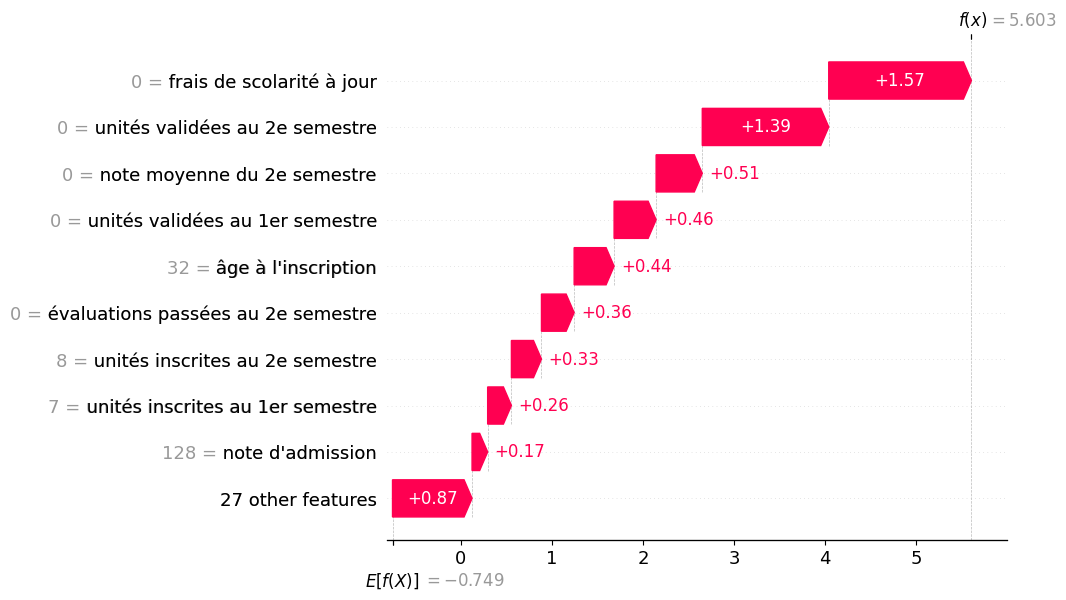

Non-abandon, risque le plus faible | étudiant n° 154
Probabilité d'abandon : 0.6% | décision au seuil 0.3 : pas d alerte | réalité : pas d abandon
Le risque d'abandon est faible (1%, sous le seuil de 30%). Facteurs qui le réduisent le plus : profession de la mère (code 191), unités validées au 2e semestre (6) et filière (code 9238). Facteur qui l'augmente : dette envers l'établissement (oui).


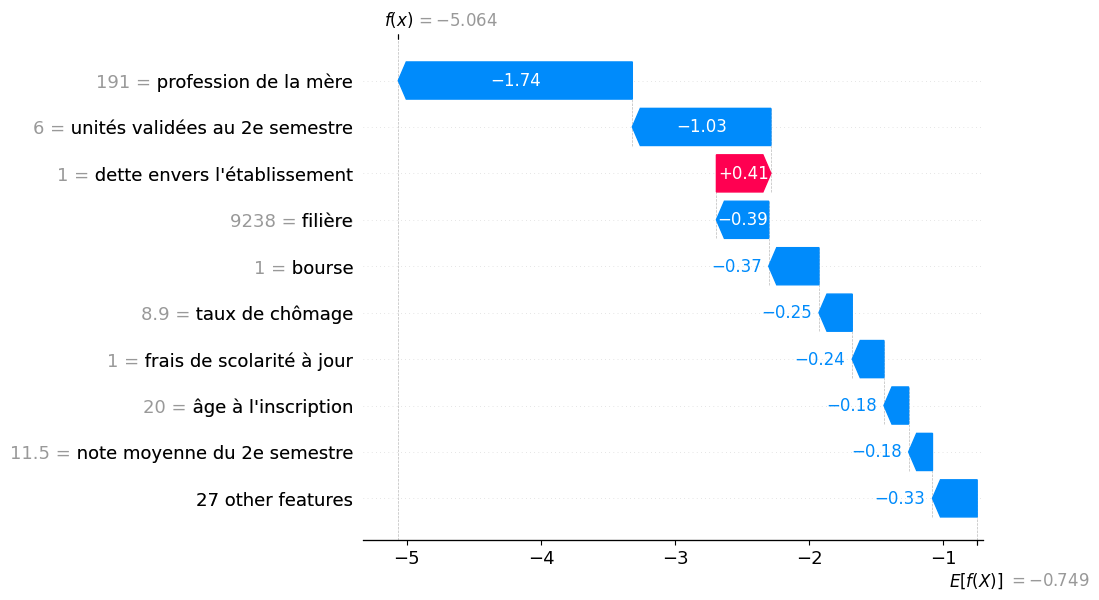

Abandon non détecté (probabilité minimale) | étudiant n° 709
Probabilité d'abandon : 2.7% | décision au seuil 0.3 : pas d alerte | réalité : abandon
Le risque d'abandon est faible (3%, sous le seuil de 30%). Facteurs qui le réduisent le plus : unités validées au 2e semestre (7), unités validées au 1er semestre (7) et bourse (oui).


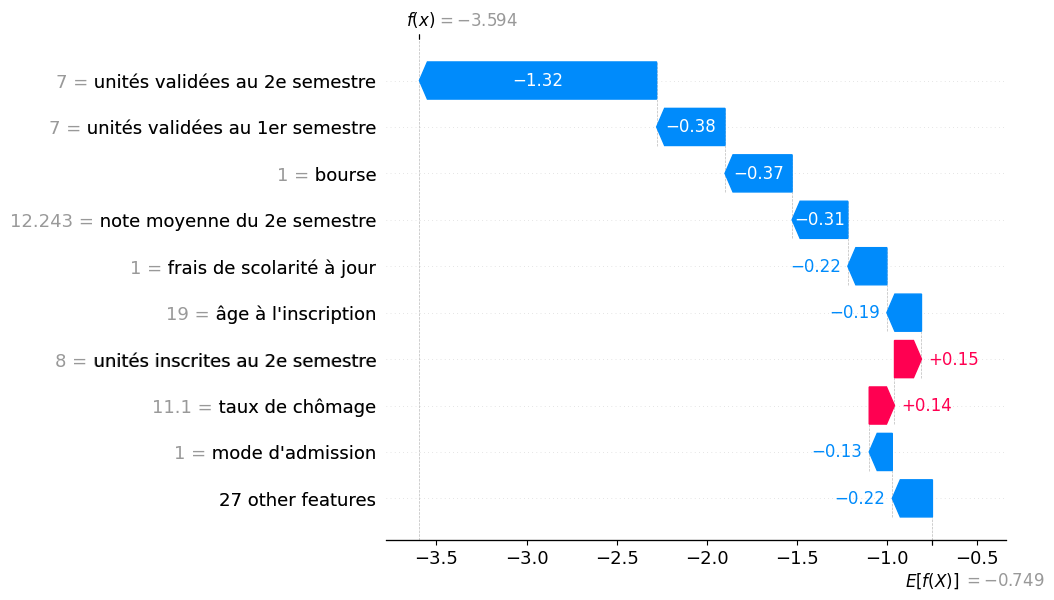

In [36]:
yv = y_test.values
cas = {
    "Abandon correctement signalé (probabilité maximale)": int(np.argmax(np.where(yv == 1, p_xgb, -1))),
    "Non-abandon, risque le plus faible": int(np.argmin(np.where(yv == 0, p_xgb, 2))),
    "Abandon non détecté (probabilité minimale)": int(np.argmin(np.where(yv == 1, p_xgb, 2))),
}
noms_fr = [LABELS[c] for c in raw_cols]

def waterfall(i):
    e = shap.Explanation(values=sv_raw[i], base_values=base,
                         data=X_test.iloc[i].values.astype(float), feature_names=noms_fr)
    shap.plots.waterfall(e, max_display=10)

for titre, i in cas.items():
    print("=" * 70)
    print(titre, "| étudiant n°", i)
    print(f"Probabilité d'abandon : {p_xgb[i]:.1%} | décision au seuil {SEUIL} : "
          f"{'ALERTE' if p_xgb[i] >= SEUIL else 'pas d alerte'} | réalité : "
          f"{'abandon' if yv[i] == 1 else 'pas d abandon'}")
    print(phrase(i))
    waterfall(i)

In [39]:
from lime.lime_tabular import LimeTabularExplainer

int_cols = categorical_cols + binary_cols
cat_idx = [raw_cols.index(c) for c in int_cols]          # LIME traite ces colonnes comme des catégories

def nouvel_explainer(seed=42):
    return LimeTabularExplainer(X_train.values.astype(float), feature_names=raw_cols,
                                categorical_features=cat_idx, class_names=["reste", "abandon"],
                                discretize_continuous=True, random_state=seed)

lime_explainer = nouvel_explainer()

def predict_fn(arr):                                      # LIME envoie des tableaux : on refait un DataFrame
    d = pd.DataFrame(arr, columns=raw_cols)
    d[int_cols] = d[int_cols].round().astype(int)
    return xgb_pipe.predict_proba(d)

def lime_contrib(i, explainer=None, num_samples=5000, k=None):
    explainer = explainer or lime_explainer
    exp = explainer.explain_instance(X_test.iloc[i].values.astype(float), predict_fn,
                                     num_features=k or len(raw_cols), num_samples=num_samples)
    w = dict(exp.as_map()[1])
    return pd.Series({raw_cols[j]: v for j, v in w.items()}).reindex(raw_cols).fillna(0.0), exp

def comparer(i, k=5):
    s = pd.Series(sv_raw[i], index=raw_cols)
    l, exp = lime_contrib(i)
    top_s = list(s.abs().sort_values(ascending=False).head(k).index)
    top_l = list(l.abs().sort_values(ascending=False).head(k).index)
    union = list(dict.fromkeys(top_s + top_l))
    tab = pd.DataFrame({"SHAP (log-odds)": s[union].round(2), "LIME (poids)": l[union].round(3)})
    tab.index = [LABELS[v] for v in union]
    tab["Même sens"] = np.where(np.sign(s[union]).values == np.sign(l[union]).values, "oui", "NON")
    print(tab.to_string())
    print(f"Variables communes aux deux listes de {k} : {len(set(top_s) & set(top_l))} sur {k}")
    print(f"Corrélation de rang (Spearman) sur les 36 variables : "
          f"{s.abs().corr(l.abs(), method='spearman'):.2f}")
    print("Conditions retenues par LIME :", [(t, round(w, 3)) for t, w in exp.as_list()[:4]])

def stabilite(i, n=5, k=3):
    """LIME est aléatoire : on le relance avec n graines différentes."""
    tops = []
    for seed in range(n):
        _, e = lime_contrib(i, explainer=nouvel_explainer(seed), k=k)
        tops.append(tuple(sorted(raw_cols[j] for j, _ in e.as_map()[1])))
    return len(set(tops))

In [40]:
for titre, i in cas.items():
    print("=" * 70)
    print(titre, "| étudiant n°", i)
    comparer(i)
    print(f"Stabilité de LIME : {stabilite(i)} liste(s) différente(s) de 3 variables sur 5 exécutions")

Abandon correctement signalé (probabilité maximale) | étudiant n° 860
                                 SHAP (log-odds)  LIME (poids) Même sens
frais de scolarité à jour                   1.57         0.357       oui
unités validées au 2e semestre              1.39         0.405       oui
note moyenne du 2e semestre                 0.51         0.148       oui
unités validées au 1er semestre             0.46         0.100       oui
âge à l'inscription                         0.44         0.089       oui
unités créditées au 2e semestre            -0.05        -0.093       oui
Variables communes aux deux listes de 5 : 4 sur 5
Corrélation de rang (Spearman) sur les 36 variables : 0.72
Conditions retenues par LIME : [('Curricular units 2nd sem (approved) <= 2.00', 0.405), ('Tuition fees up to date=0', 0.357), ('Curricular units 2nd sem (grade) <= 10.75', 0.148), ('Curricular units 1st sem (approved) <= 3.00', 0.1)]
Stabilité de LIME : 1 liste(s) différente(s) de 3 variables sur 5 exécutions

In [41]:
def categories(var, top=8):
    """Pour chaque catégorie d'une variable : contribution SHAP moyenne et effectifs."""
    j = raw_cols.index(var)
    g = (pd.DataFrame({"code": X_test[var].values, "shap": sv_raw[:, j]})
         .groupby("code")["shap"].agg(["mean", "count"]))
    g.columns = ["SHAP moyen (log-odds)", "Étudiants (test)"]
    tr = (pd.DataFrame({"code": X_train[var].values, "y": y_train.values})
          .groupby("code")["y"].agg(["mean", "count"]))
    tr.columns = ["Taux d'abandon (train)", "Étudiants (train)"]
    out = g.join(tr, how="left")
    ordre = out["SHAP moyen (log-odds)"].abs().sort_values(ascending=False).index
    return out.loc[ordre].head(top).round(3)

print("Profession de la mère : catégories qui pèsent le plus")
print(categories("Mother's occupation").to_string())
print("\nFilière : catégories qui pèsent le plus")
print(categories("Course", 6).to_string())

m191 = X_train["Mother's occupation"] == 191
print("\nCode 191 dans l'entraînement :", int(m191.sum()), "étudiants, taux d'abandon",
      round(float(y_train[m191].mean()), 3) if m191.sum() else "n/a")

Profession de la mère : catégories qui pèsent le plus
      SHAP moyen (log-odds)  Étudiants (test)  Taux d'abandon (train)  Étudiants (train)
code                                                                                    
191                  -1.834                 4                   0.000               22.0
0                     0.570                32                   0.705              112.0
8                     0.380                 5                   0.484               31.0
90                    0.337                16                   0.704               54.0
7                     0.085                77                   0.303              195.0
2                    -0.051                51                   0.333              267.0
9                    -0.048               318                   0.304             1259.0
192                  -0.044                 1                   0.000                4.0

Filière : catégories qui pèsent le plus
      SHAP moye

In [42]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, precision_score, recall_score

parentales = ["Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

def proba_sans(retirer):
    cs = [c for c in raw_cols if c not in retirer]
    prep_s = ColumnTransformer([
        ("num", StandardScaler(), [c for c in numeric_cols if c in cs]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         [c for c in categorical_cols if c in cs]),
        ("bin", "passthrough", [c for c in binary_cols if c in cs]),
    ])
    m = Pipeline([("prep", prep_s), ("clf", clone(xgb_pipe.named_steps["clf"]))])
    return m.fit(X_train[cs], y_train).predict_proba(X_test[cs])[:, 1]

def ecarts(proba):
    pred, yy = proba >= thr, y_test.values
    g, a = X_test["Gender"].values, X_test["Age at enrollment"].values
    fp = lambda m: (pred & (yy == 0) & m).sum() / max(((yy == 0) & m).sum(), 1)
    rc = lambda m: (pred & (yy == 1) & m).sum() / max(((yy == 1) & m).sum(), 1)
    return (f"fausses alertes genre 0 / 1 : {fp(g == 0):.3f} / {fp(g == 1):.3f} | "
            f"rappel 22 ans ou moins / plus : {rc(a <= 22):.3f} / {rc(a > 22):.3f}")

for nom, proba in [("modèle d'origine", p0),
                   ("sans variables sensibles", proba_sans(sensibles)),
                   ("sans sensibles ni variables des parents", proba_sans(sensibles + parentales))]:
    pred = proba >= thr
    print(f"{nom:42s} AUC = {roc_auc_score(y_test, proba):.3f} | "
          f"rappel = {recall_score(y_test, pred):.3f} | précision = {precision_score(y_test, pred):.3f}")
    print("   ", ecarts(proba))

modèle d'origine                           AUC = 0.936 | rappel = 0.856 | précision = 0.786
    fausses alertes genre 0 / 1 : 0.077 / 0.189 | rappel 22 ans ou moins / plus : 0.758 / 0.941
sans variables sensibles                   AUC = 0.934 | rappel = 0.856 | précision = 0.774
    fausses alertes genre 0 / 1 : 0.094 / 0.177 | rappel 22 ans ou moins / plus : 0.758 / 0.941
sans sensibles ni variables des parents    AUC = 0.936 | rappel = 0.866 | précision = 0.774
    fausses alertes genre 0 / 1 : 0.094 / 0.183 | rappel 22 ans ou moins / plus : 0.773 / 0.947
